# Audio Exploration
- Summarize training audio and inspect selected examples.
- Patient labels describe the patient, not necessarily an audible murmur at every location.
- This notebook does not create model training features or modify raw audio.

#### Loading the recording index
- Run create_indexes.py and split_patients.py first.
- Use training recordings to investigate preprocessing choices.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
from scipy.signal import spectrogram
from IPython.display import Audio, display

plt.style.use("dark_background")

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

OUTPUT_DIR = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT))

from src.preprocessing.audio_preprocessing import preprocess_audio, create_windows

recordings = pd.read_csv(
    OUTPUT_DIR / "recording_index.csv", dtype={"patient_id": str}
)
if "split" not in recordings.columns:
    raise ValueError("Run split_patients.py before this notebook.")

training = recordings.loc[
    (recordings["split"] == "train") &
    recordings["murmur_label"].isin(["Present", "Absent"])
].copy()
if training.empty:
    raise ValueError("No labeled training recordings found.")

print("Training patients:", training["patient_id"].nunique())
print("Training recordings:", len(training))

Training patients: 611
Training recordings: 2098


#### Training audio overview
- Read one file at a time to keep memory use low.
- Peak and RMS describe amplitude, not whether a recording is clinically usable.
- Near-zero samples use an absolute threshold of 0.001; this is a rough amplitude measure, not a silence detector.
- Samples near full scale may indicate clipping, but this does not prove clipping occurred.

In [2]:
audio_rows = []
issues = []

for row in training.itertuples(index=False):
    try:
        signal, sr = sf.read(ROOT / row.audio_path, dtype="float32")
        if signal.size == 0 or not np.isfinite(signal).all():
            raise ValueError("Empty or nonfinite audio")

        # Check full-scale samples before combining channels.
        near_full_scale = np.mean(np.abs(signal) >= 0.999) * 100
        if signal.ndim > 1:
            signal = signal.mean(axis=1)

        audio_rows.append({
            "audio_path": row.audio_path,
            "patient_id": row.patient_id,
            "murmur_label": row.murmur_label,
            "location": row.location,
            "sample_rate": sr,
            "duration_seconds": len(signal) / sr,
            "peak": np.max(np.abs(signal)),
            "rms": np.sqrt(np.mean(signal.astype(float) ** 2)),
            "mean": np.mean(signal),
            "near_zero_percent": np.mean(np.abs(signal) < 0.001) * 100,
            "near_full_scale_percent": near_full_scale
        })
    except Exception as error:
        issues.append({"audio_path": row.audio_path, "error": str(error)})

stats = pd.DataFrame(audio_rows)
print("Recordings checked:", len(stats))
print("Failed recordings:", len(issues))
if issues:
    print(pd.DataFrame(issues).to_string(index=False))
    raise ValueError("Resolve audio issues before continuing.")

columns = ["duration_seconds", "peak", "rms", "mean",
           "near_zero_percent", "near_full_scale_percent"]
print(stats[columns].describe().round(4).to_string())
print("\nMedian values by patient label (recording-level summaries):")
print(stats.groupby("murmur_label")[columns].median().round(4).to_string())

Recordings checked: 2098
Failed recordings: 0
       duration_seconds       peak        rms       mean  near_zero_percent  near_full_scale_percent
count         2098.0000  2098.0000  2098.0000  2098.0000          2098.0000                2098.0000
mean            23.2065     0.9544     0.0481     0.0000             8.9000                   0.0239
std              7.3653     0.0959     0.0372     0.0008             4.1741                   0.1111
min              5.6800     0.3063     0.0076    -0.0035             0.6133                   0.0000
25%             19.2480     0.9501     0.0274    -0.0003             5.8073                   0.0000
50%             21.7440     1.0000     0.0376     0.0000             8.3245                   0.0035
75%             29.6480     1.0000     0.0545     0.0004            11.4040                   0.0126
max             64.5120     1.0000     0.4006     0.0046            48.2996                   2.9031

Median values by patient label (recording-le

#### Audio distributions
- Each observation is one recording; patients with more recordings contribute more observations.

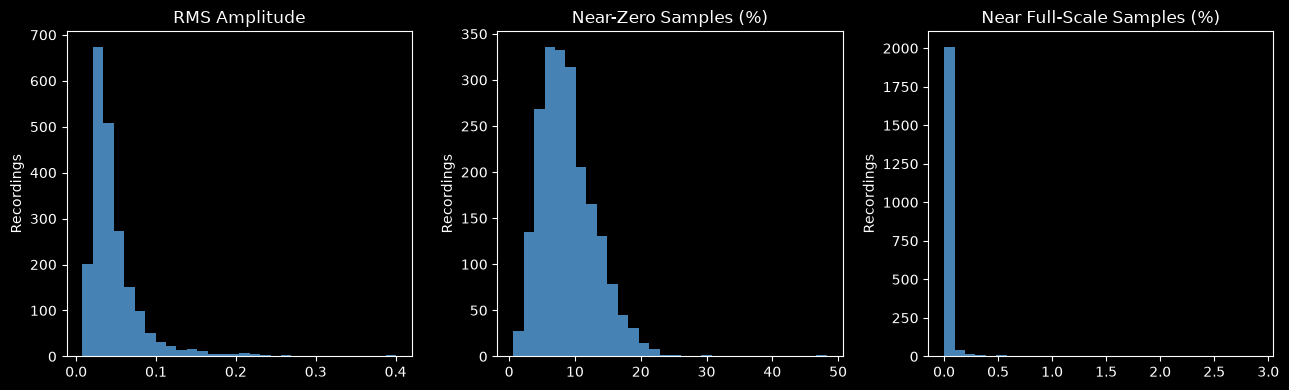

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, column, title in zip(
    axes,
    ["rms", "near_zero_percent", "near_full_scale_percent"],
    ["RMS Amplitude", "Near-Zero Samples (%)", "Near Full-Scale Samples (%)"]
):
    ax.hist(stats[column], bins=30, color="steelblue")
    ax.set_title(title)
    ax.set_ylabel("Recordings")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "training_audio_statistics.png", dpi=200)
plt.show()
plt.close(fig)

#### Selecting examples
- Select one recording per patient label and recording location, with a fixed seed.
- Add the shortest and longest training recordings. These examples are for inspection, not evidence of class-specific sound patterns.

In [4]:
examples = pd.concat([
    stats.groupby(["murmur_label", "location"], group_keys=False).sample(
        n=1, random_state=42
    ),
    stats.nsmallest(1, "duration_seconds"),
    stats.nlargest(1, "duration_seconds")
]).drop_duplicates("audio_path").reset_index(drop=True)

print(examples[["patient_id", "murmur_label", "location", "duration_seconds"]]
      .round(2).to_string(index=False))

patient_id murmur_label location  duration_seconds
     85157       Absent       AV              9.89
     50057       Absent       MV             24.59
     50788       Absent       PV             30.80
     50216       Absent      Phc             26.50
     85265       Absent       TV             25.90
     50220      Present       AV             29.95
     84702      Present       MV             17.25
     50280      Present       PV             27.95
     50734      Present      Phc             30.35
     85198      Present       TV             19.95
     50216       Absent      Phc              5.68
     50734      Present       AV             64.51


#### Original and processed audio
- Use the existing function: mono conversion, mean removal, 25–800 Hz bandpass filtering, and peak normalization.
- Shared amplitude limits prevent automatic plot scaling from hiding differences.
- The function resamples to 4,000 Hz before filtering and normalization.
- Compare recordings before adopting trimming or alternative normalization rules.

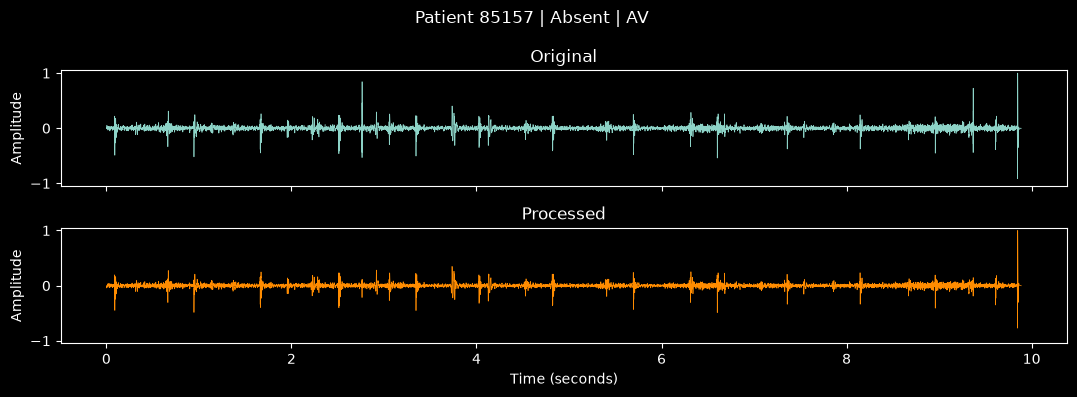

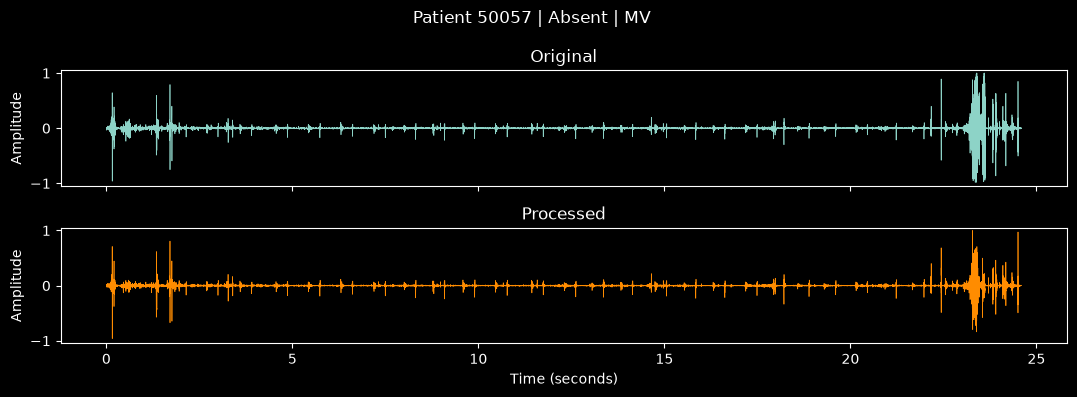

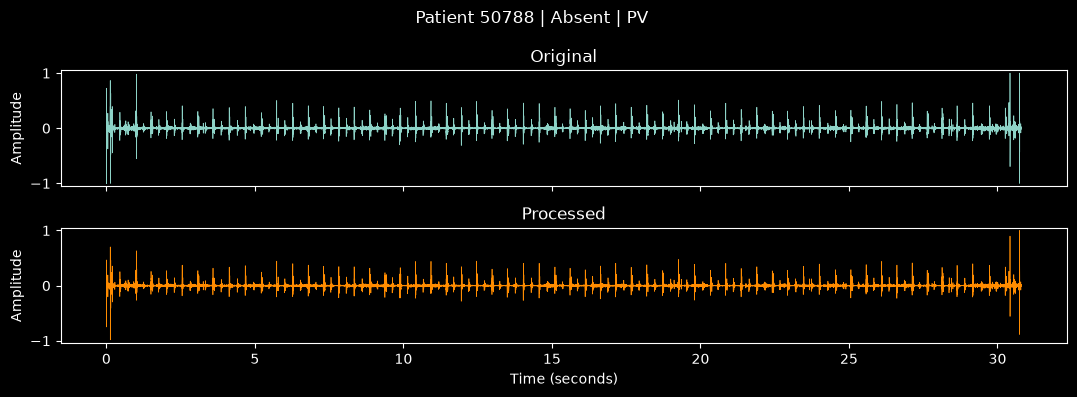

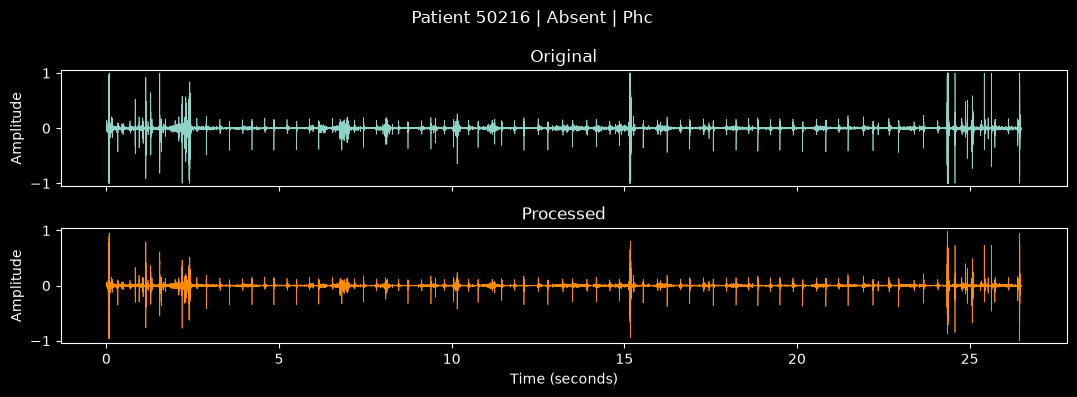

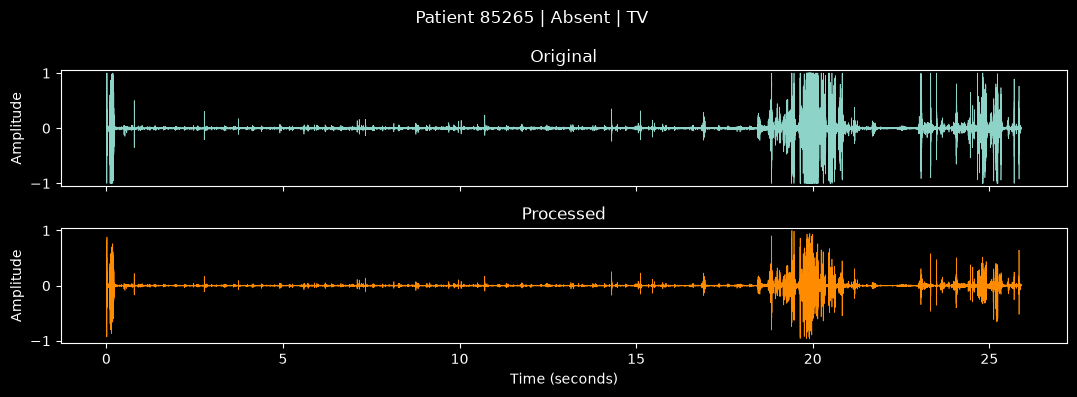

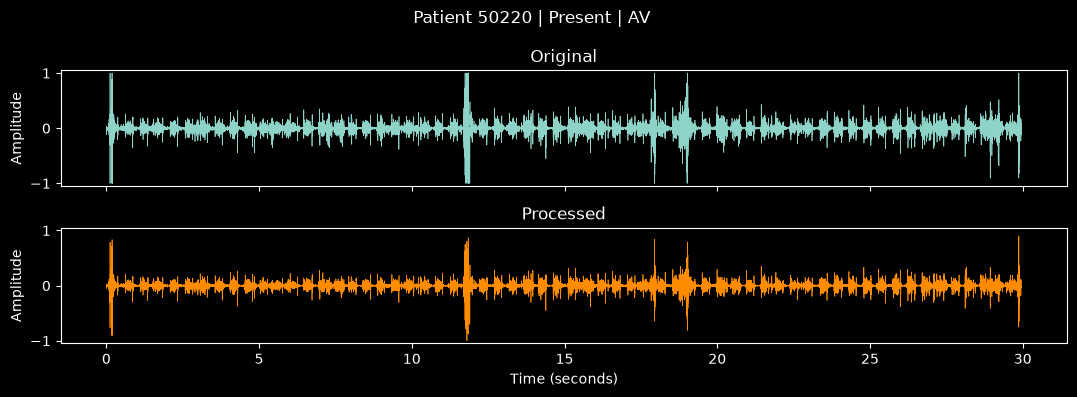

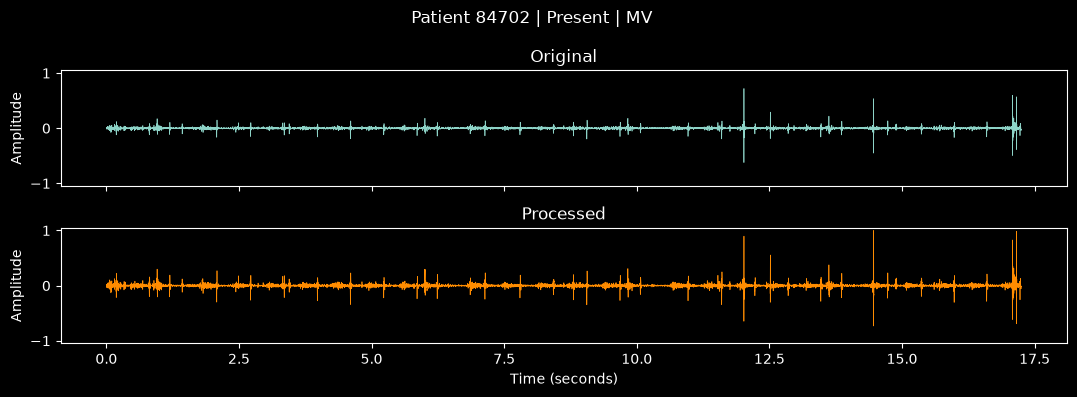

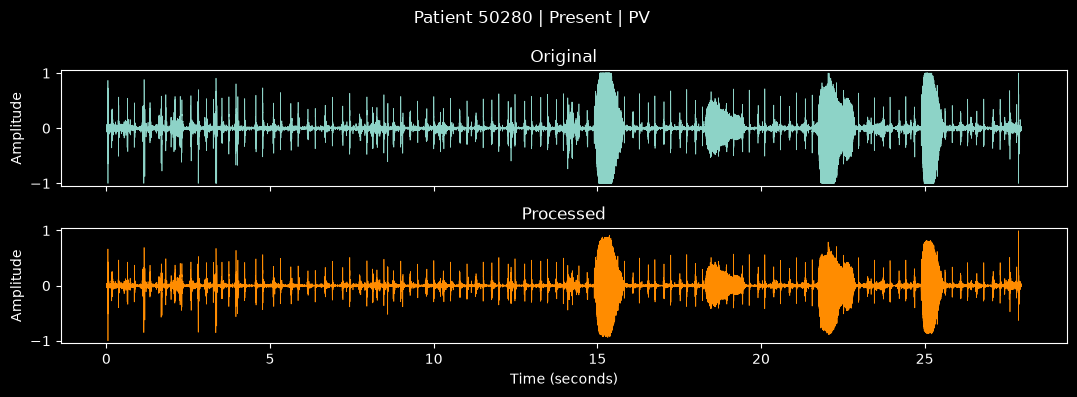

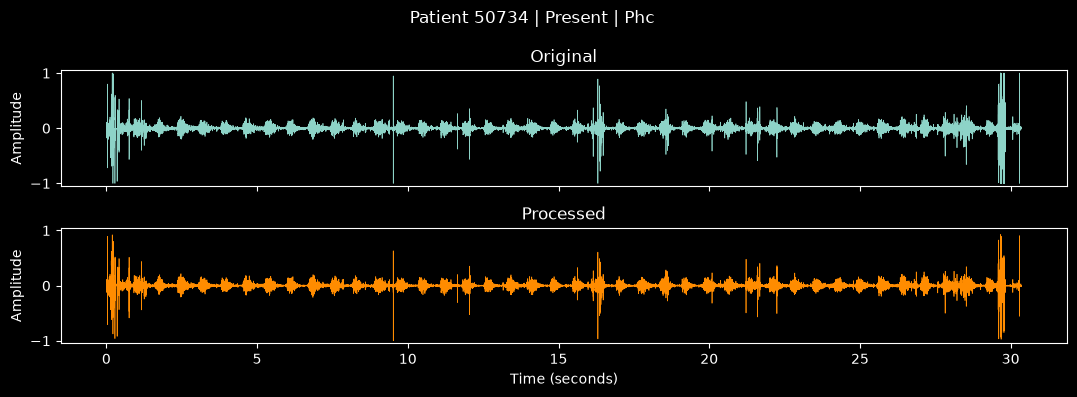

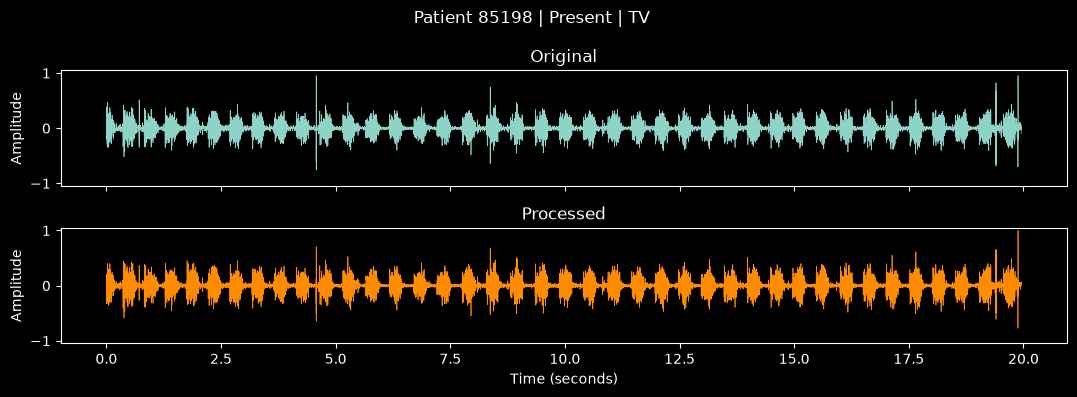

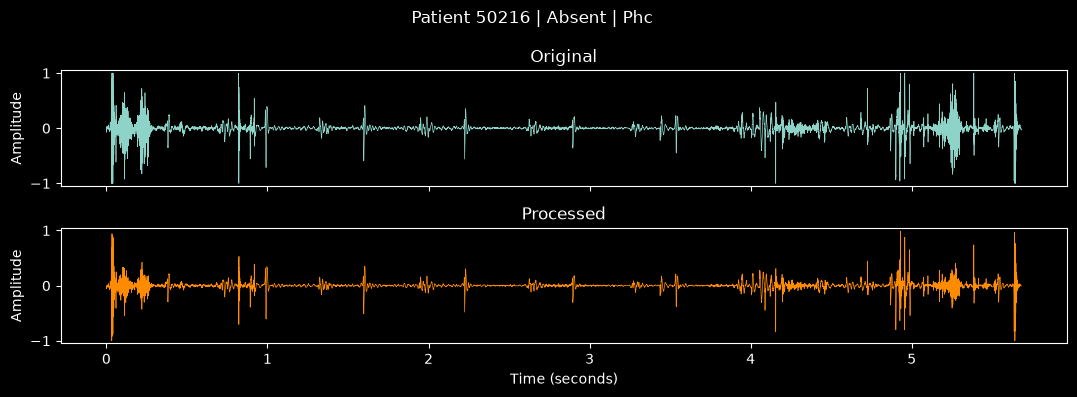

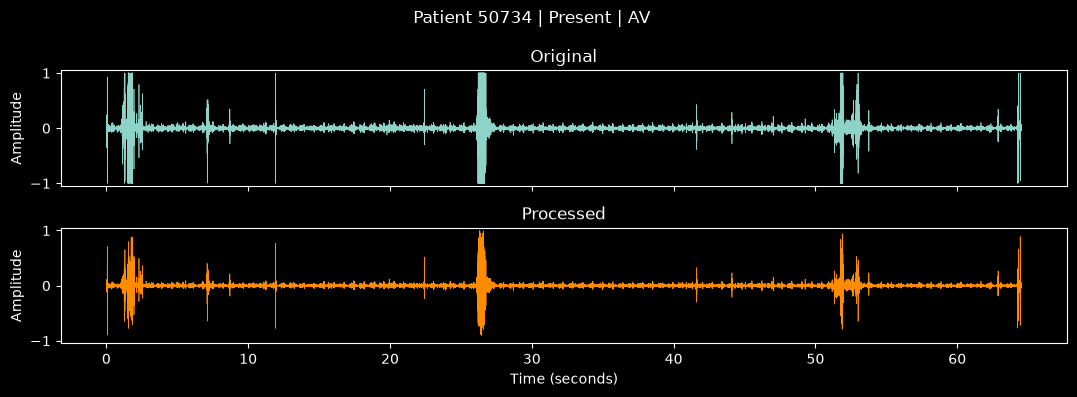

In [5]:
for row in examples.itertuples(index=False):
    original, sr = sf.read(ROOT / row.audio_path)
    if original.ndim > 1:
        original = original.mean(axis=1)
    processed, processed_sr = preprocess_audio(ROOT / row.audio_path)

    limit = max(np.max(np.abs(original)), np.max(np.abs(processed)), 0.01) * 1.05
    fig, axes = plt.subplots(2, 1, figsize=(11, 4), sharex=True, sharey=True)
    axes[0].plot(np.arange(len(original)) / sr, original, linewidth=0.5)
    axes[0].set_title("Original")
    axes[1].plot(np.arange(len(processed)) / processed_sr, processed,
                 linewidth=0.5, color="darkorange")
    axes[1].set_title("Processed")
    axes[1].set_xlabel("Time (seconds)")
    for ax in axes:
        ax.set_ylabel("Amplitude")
        ax.set_ylim(-limit, limit)
    fig.suptitle(f"Patient {row.patient_id} | {row.murmur_label} | {row.location}")
    plt.tight_layout()
    plt.show()
    plt.close(fig)

#### Listening to one example
- Change example_number to inspect another selected recording.
- Playback normalization is disabled so the player does not independently rescale the two signals.

In [6]:
example_number = 0
example = examples.iloc[example_number]
audio_path = ROOT / example["audio_path"]
original, sr = sf.read(audio_path)
if original.ndim > 1:
    original = original.mean(axis=1)
processed, processed_sr = preprocess_audio(audio_path)

print("File:", audio_path.name)
print("Patient label:", example["murmur_label"])
print("Original sample rate:", sr)
print("Processed sample rate:", processed_sr)
print("Original audio:")
display(Audio(original, rate=sr, normalize=False))
print("Processed audio:")
display(Audio(processed, rate=processed_sr, normalize=False))

File: 85157_AV.wav
Patient label: Absent
Original sample rate: 4000
Processed sample rate: 4000
Original audio:


Processed audio:


#### Fixed-length windows
- Split the processed example into consecutive 4-second windows, without overlap.
- At 4,000 Hz, each window contains 16,000 samples. Zero-pad the final remainder rather than discarding it.
- Normalization happens per recording before windowing. Padding is tracked and does not add real audio.

Windows: 3
Samples per window: 16000
Final window valid samples: 7552
Final window padded samples: 8448


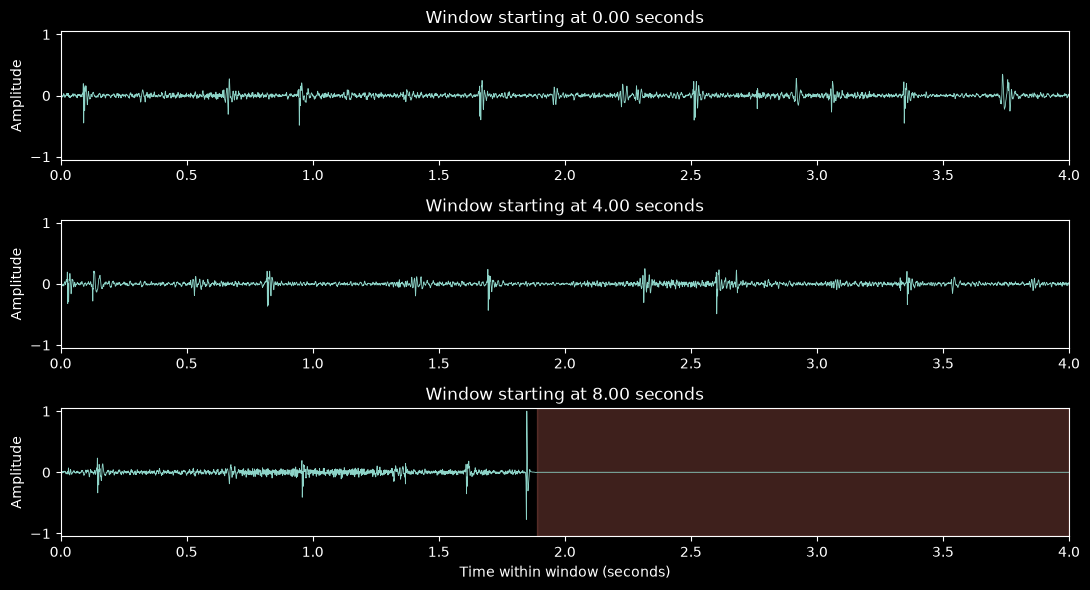

First window playback:


In [7]:
window_seconds = 4
windows = list(create_windows(processed, processed_sr, window_seconds))
print("Windows:", len(windows))
print("Samples per window:", len(windows[0][0]))
print("Final window valid samples:", windows[-1][2])
print("Final window padded samples:", len(windows[-1][0]) - windows[-1][2])

fig, axes = plt.subplots(min(3, len(windows)), 1, figsize=(11, 6), squeeze=False)
for ax, (window, start, valid) in zip(axes[:, 0], windows[:3]):
    ax.plot(np.arange(len(window)) / processed_sr, window, linewidth=0.6)
    if valid < len(window):
        ax.axvspan(valid / processed_sr, window_seconds, alpha=0.25, color="salmon")
    ax.set_title(f"Window starting at {start / processed_sr:.2f} seconds")
    ax.set_ylabel("Amplitude")
    ax.set_xlim(0, window_seconds)
    ax.set_ylim(-1.05, 1.05)
axes[-1, 0].set_xlabel("Time within window (seconds)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "audio_example_windows.png", dpi=200)
plt.show()
plt.close(fig)

example_window = windows[0][0]
print("First window playback:")
display(Audio(example_window, rate=processed_sr, normalize=False))

#### Spectrogram and MFCC example
- A spectrogram shows how frequency energy changes over time. This is a standard power spectrogram, not the CNN log-Mel input.
- MFCCs summarize spectral patterns. The baseline helper reduces 13 coefficients to 26 values: a mean and standard deviation per coefficient.
- This example uses processed audio; the features below use the selected 4-second window.

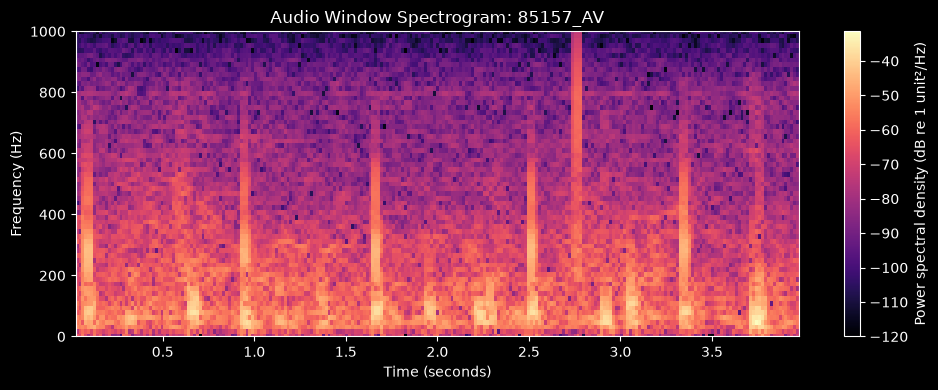

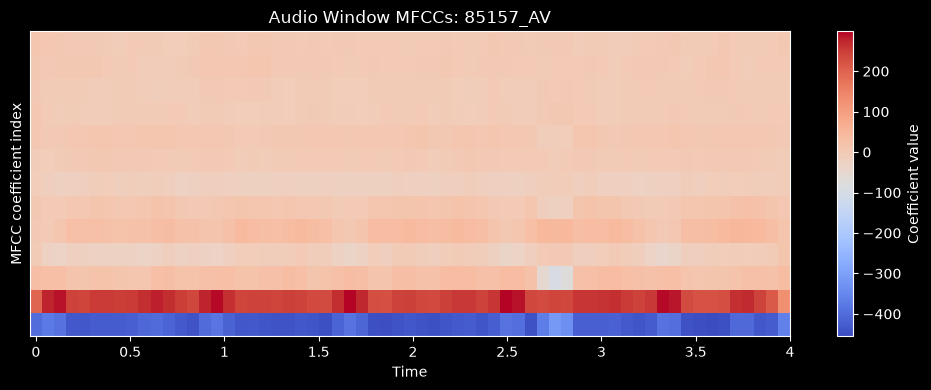

MFCC matrix shape: (13, 63)
Baseline feature vector shape: (26,)
All features finite: True


In [8]:
import librosa
import librosa.display
from src.features.extract_features import extract_mfcc_features

frequencies, times, power = spectrogram(
    example_window, fs=processed_sr, nperseg=256, noverlap=192
)
fig, ax = plt.subplots(figsize=(10, 4))
mesh = ax.pcolormesh(times, frequencies, 10 * np.log10(power + 1e-12),
                     shading="auto", cmap="magma")
ax.set_ylim(0, min(1000, processed_sr / 2))
ax.set_title("Audio Window Spectrogram: " + audio_path.stem)
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Frequency (Hz)")
fig.colorbar(mesh, ax=ax, label="Power spectral density (dB re 1 unit²/Hz)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "audio_example_spectrogram.png", dpi=200)
plt.show()
plt.close(fig)

mfccs = librosa.feature.mfcc(
    y=example_window, sr=processed_sr,
    n_mfcc=13, n_fft=1024, hop_length=256
)
fig, ax = plt.subplots(figsize=(10, 4))
mesh = librosa.display.specshow(
    mfccs, sr=processed_sr, hop_length=256, x_axis="time", ax=ax, cmap="coolwarm"
)
ax.set_title("Audio Window MFCCs: " + audio_path.stem)
ax.set_ylabel("MFCC coefficient index")
fig.colorbar(mesh, ax=ax, label="Coefficient value")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "audio_example_mfcc.png", dpi=200)
plt.show()
plt.close(fig)

features = extract_mfcc_features(example_window, processed_sr)
print("MFCC matrix shape:", mfccs.shape)
print("Baseline feature vector shape:", features.shape)
print("All features finite:", np.isfinite(features).all())